Chargement des donénes

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

Ts = 0.05  # période d'échantillonnage [s]

# Lecture des deux fichiers (sans ligne d'en-tête)
U = pd.read_csv("../data/raw/bdd_in_mat_05.csv", header=None).to_numpy()   # commandes u
Y = pd.read_csv("../data/raw/bdd_out_mat_05.csv", header=None).to_numpy()  # mesures

print("U :", U.shape, "  Y :", Y.shape)

#Header = None indique à Pandas que le fichier n'a pas de ligne de titres

U : (3000, 2000)   Y : (3000, 2000)


## Data exploration 

Regarder quelques expériences, u is a normalized vertical thrust command.

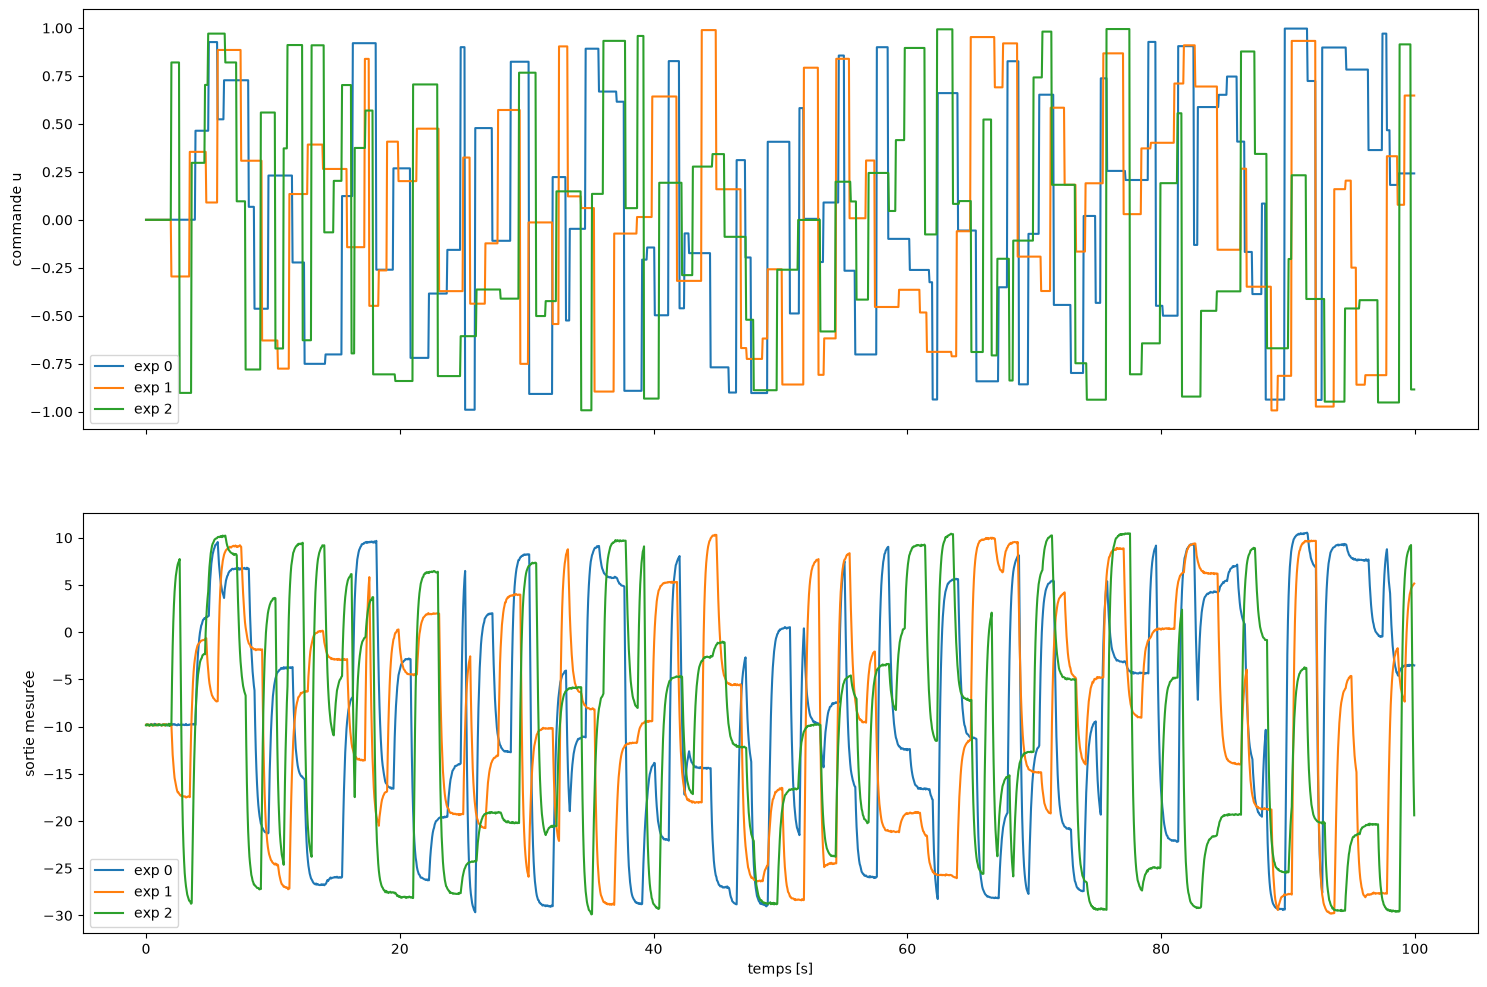

In [3]:
t = np.arange(U.shape[1]) * Ts  # axe du temps en secondes

fig, axes = plt.subplots(2, 1, figsize=(18, 12), sharex=True)
#2, 1 : 2 lignes et 1 colonne donc 2 graphes empilés
#figsize=(12, 6) -> taille de la figure en pouces : 12 de large, 6 de haut
#sharex = True -> les deux graphes partagent le même axe x
for i in [0, 1, 2]:                       # 3 premières expériences
    axes[0].plot(t, U[i], label=f"exp {i}")
    axes[1].plot(t, Y[i], label=f"exp {i}")
axes[0].set_ylabel("commande u")
axes[1].set_ylabel("sortie mesurée")
axes[1].set_xlabel("temps [s]")
axes[0].legend(); axes[1].legend() # = plt.legend()
plt.show()

Global statistics


u  min / max : -0.999980222206112 0.999992242074338
y  min / max : -341.099204721116 412.925797764055
y percentiles 0.01% / 1% / 50% / 99% / 99.99% : [-98.03570687 -29.57969189  -9.8141392    9.97905222 102.00225264]


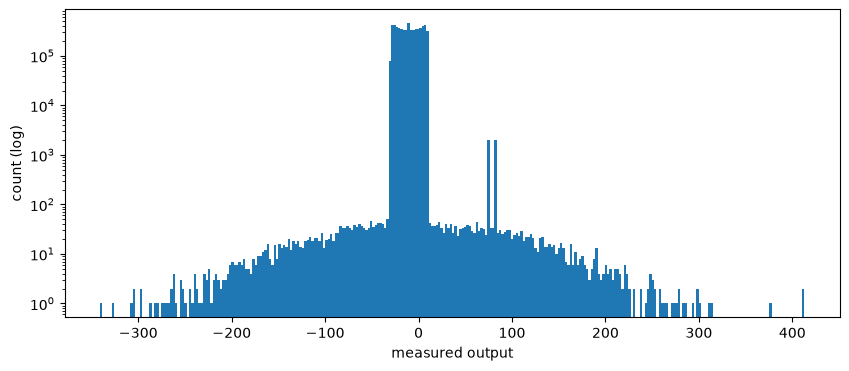

In [4]:
print("u  min / max :", U.min(), U.max())
print("y  min / max :", Y.min(), Y.max())
print("y percentiles 0.01% / 1% / 50% / 99% / 99.99% :",
      np.percentile(Y, [0.01, 1, 50, 99, 99.99]))

plt.figure(figsize=(10, 4))
plt.hist(Y.ravel(), bins=300, log=True)   # log scale so rare values stay visible
# bins=300 set ow many abrs the histogram has
plt.xlabel("measured output"); plt.ylabel("count (log)")
plt.show()

Find the outliers

outlier samples   : 7052 (0.1175 % of the data)
experiments hit   : 4 / 3000
[ 122  455 1233 1677]


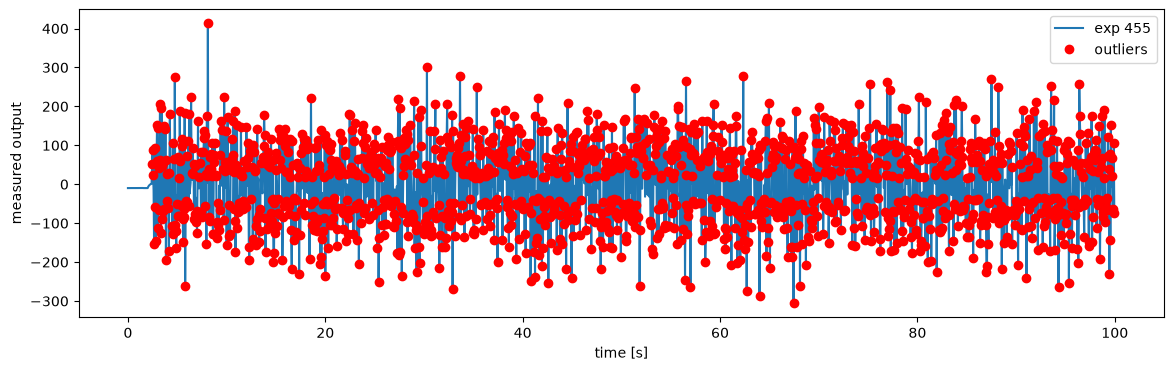

In [5]:
# Provisional bounds, taken from what we saw: normal values stay in about [-30, 10]
low, high = -35, 15
mask = (Y < low) | (Y > high)

print("outlier samples   :", mask.sum(), f"({100 * mask.mean():.4f} % of the data)")
rows = np.where(mask.any(axis=1))[0]
print("experiments hit   :", len(rows), "/", Y.shape[0])

# Plot the first affected experiment, with outliers in red
i = rows[1]
print(rows)
plt.figure(figsize=(14, 4))
plt.plot(t, Y[i], label=f"exp {i}")
plt.plot(t[mask[i]], Y[i][mask[i]], "ro", label="outliers")
plt.xlabel("time [s]"); plt.ylabel("measured output"); plt.legend()
plt.show()

An experiment is rejected if more than 1 % of its samples fall outside the physical range $[-35, 15]$. Experiments with only a few out-of-range samples would have those samples interpolated (none occur in this dataset).

Zoom on the dynamics

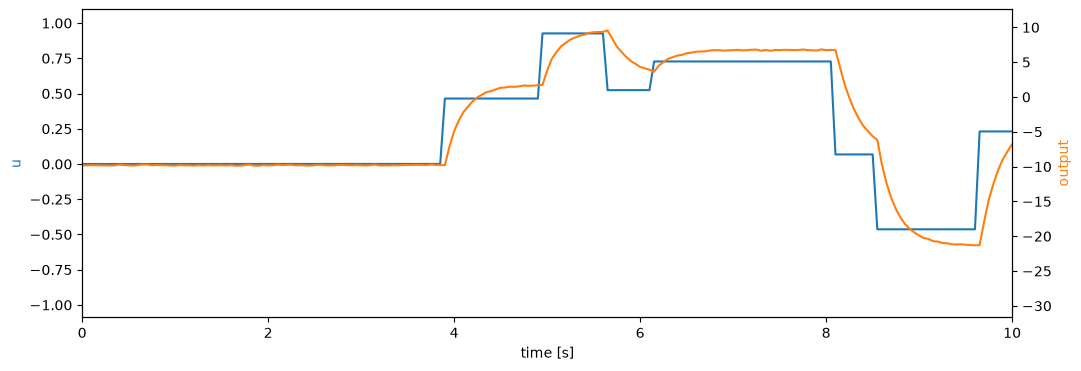

In [6]:
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(t, U[0], "C0", label="u")
ax1.set_ylabel("u", color="C0")
ax2 = ax1.twinx()                        # second y axis on the right
ax2.plot(t, Y[0], "C1", label="output")
ax2.set_ylabel("output", color="C1")
ax1.set_xlim(0, 10)                      # first 10 seconds only
ax1.set_xlabel("time [s]")
plt.show()

## Summary of the data exploration

- **Shape:** 3000 experiments × 2000 samples (Ts = 0.05 s, i.e. 100 s each). No NaN.
- **Input u:** in [-1, 1]. u = 0 for the first ~2 s, then random piecewise-constant steps, uniformly distributed.
- **Output y:** vertical acceleration a_z [m/s²]. y = -9.81 (= -g) when u = 0. Normal range about [-30, 10].
- **Static characteristic** (steady state):

| u | -1 | -0.5 | 0 | 0.5 | 1 |
|---|----|------|---|-----|---|
| a_z | -29.9 | -22.0 | -9.81 | 2.4 | 10.3 |

  Gain ≈ 24 around u = 0 and ≈ 16 near ±1 (saturation), so the system is nonlinear. Hover (a_z = 0) at u ≈ 0.4.
- **Histogram:** the flat top comes from the uniform input passed through a near-linear gain. It reflects the excitation signal, not the flight.
- **Corrupted experiments:** 122 and 1677 (sensor stuck at 75.0 and 82.3 from step 49), 455 and 1233 (pure noise from step ~50). Remove them.
- **Next steps:** step-response analysis (delay, time constant), then identification. Altitude z is obtained by integrating a_z twice.


Correction of the database

(2996, 2000) (2996, 2000)


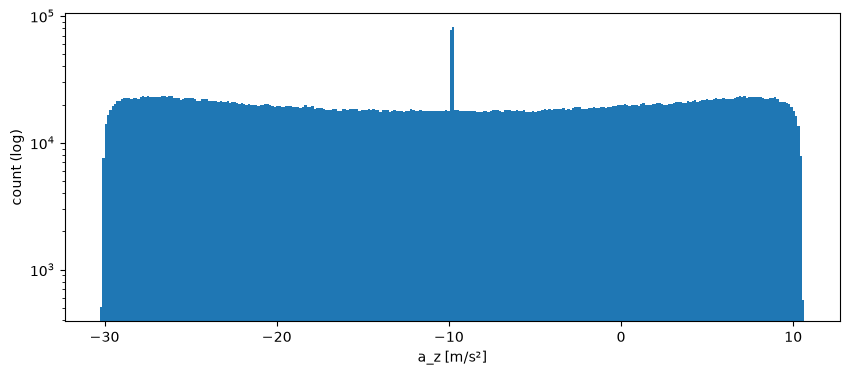

In [7]:
bad = [122, 455, 1233, 1677]
Uc, Yc = np.delete(U, bad, 0), np.delete(Y, bad, 0)
#the 0 is the acis: it tells np.delete along which dimension to delete
print(Uc.shape, Yc.shape)
plt.figure(figsize=(10, 4))
plt.hist(Yc.ravel(), bins=300, log=True)
plt.xlabel("a_z [m/s²]"); plt.ylabel("count (log)")
plt.show()


Analyse order 1

95 steps, 49 long_enough
43 response kept


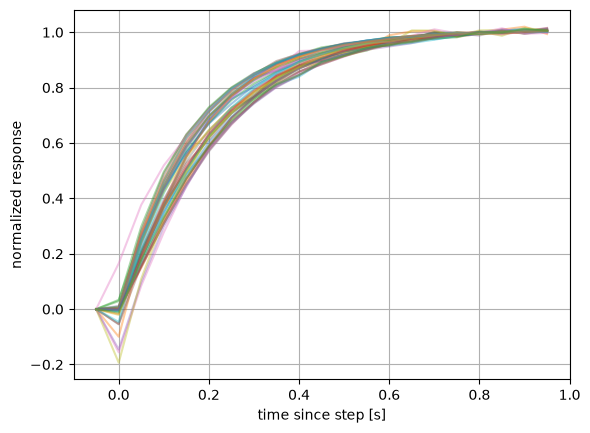

In [8]:
u = Uc[0]
changes = np.diff(u)
starts = np.flatnonzero(changes) + 1
durations = np.diff(np.append(starts, len(u)))
np.append(u, 1)

long_starts = starts[durations >= 20]
print(len(starts), "steps,", len(long_starts), "long_enough")

eps = 2 #m/s^2
a = Yc[0]
curves = []
for k in long_starts:
    window = a[k-1:k+20]
    a_before = window[0]
    a_final = window[-5:].mean()
    if abs(a_final-a_before) < eps:
        continue
    y_norm = (window-a_before)/(a_final-a_before)
    curves.append(y_norm)

print(len(curves), "response kept")
# curves is a list of step resposnes. Each element is the repsonse of a_z
# to one step of u, rescaled so it goes from 0 to 1. 

t_win = (np.arange(21)-1)*Ts
u = Uc[0]
for y in curves:
    plt.plot(t_win, y, alpha = 0.4)
plt.xlabel("time since step [s]"); plt.ylabel("normalized response")
plt.grid(); plt.show()


## Long Short Term Memory

Data processing

In [14]:
N = np.shape(Uc)[0]
N_training = int(N*0.7)
N_validation = int(N*0.15)
N_test = N - N_training - N_validation

rng = np.random.default_rng(0)
A = rng.permutation(N)

index_training = A[: N_training]
index_validation =  A[N_training:N_training + N_validation]
index_test = A[N_training + N_validation:]

Uc_training, Yc_training = Uc[index_training], Yc[index_training]
Uc_validation, Yc_validation = Uc[index_validation], Yc[index_validation]
Uc_test, Yc_test = Uc[index_test], Yc[index_test]

print(len(index_training), len(index_validation), len(index_test))   # 2097 449 450
print(np.intersect1d(index_training, index_test))   

scaler = MinMaxScaler(feature_range=(-1, 1)).fit(Yc_training.reshape(-1, 1)) #Par défaut c'est (0, 1)

Yc_training_mm = scaler.transform(Yc_training.reshape(-1, 1)).reshape(Yc_training.shape)
Yc_validation_mm = scaler.transform(Yc_validation.reshape(-1, 1)).reshape(Yc_validation.shape)
Yc_test_mm       = scaler.transform(Yc_test.reshape(-1, 1)).reshape(Yc_test.shape)


             # []

2097 449 450
[]


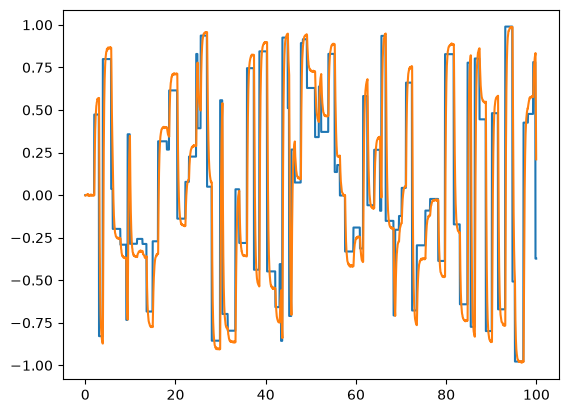

In [20]:
plt.plot(t, Uc_training[0])
plt.plot(t, Yc_training_mm[0])
plt.show()

In [22]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import lightning as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import TensorBoardLogger

Conversion to tensor

In [23]:
T_seq = 400    # 400 pas = 20 s par séquence (plus rapide à entraîner)

def to_tensors(U, Y_mm):
    X = torch.tensor(U[:, :T_seq, None], dtype=torch.float32)      # entrée : u
    Y = torch.tensor(Y_mm[:, :T_seq, None], dtype=torch.float32)   # sortie : a_z mis à l'échelle
    return X, Y
# le U[:,T_seq,None] permet d'ajouter une dimension ce qui correspond au nombre de features (ici 1 car il n'y en a pas)

X_train, Y_train = to_tensors(Uc_training,   Yc_training_mm)
X_val,   Y_val   = to_tensors(Uc_validation, Yc_validation_mm)
X_test,  Y_test  = to_tensors(Uc_test,       Yc_test_mm)

train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=32, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val, Y_val),     batch_size=32)
test_loader  = DataLoader(TensorDataset(X_test, Y_test),   batch_size=32)

print(X_train.shape, Y_train.shape)   # (2097, 400, 1) (2097, 400, 1)

torch.Size([2097, 400, 1]) torch.Size([2097, 400, 1])


### TensorDataset and DataLoader

- **`TensorDataset(X, Y)`** pairs each input sequence with its target sequence: `dataset[i]` returns `(X[i], Y[i])`, i.e. the command `u` and the scaled acceleration `a_z` of experiment `i`.
- **`DataLoader(dataset, batch_size=32, shuffle=True)`** feeds the data to the network in batches of 32 experiments, each of shape `(32, 400, 1)` = (batch, time steps, features).
  - `shuffle=True` (training only): the order of the **experiments** is randomized at every epoch. The time order **inside** each sequence is never changed, which a dynamic model needs.
  - Validation and test loaders are not shuffled: they are only used for evaluation.
- One pass over `train_loader` = one epoch (66 batches for 2097 training experiments).


Model

In [25]:
class model_nn(L.LightningModule):
    def __init__(self, hidden_size=32, lr=1e-3):
        super().__init__()
        self.save_hyperparameters()
        self.rnn = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)
        self.loss_fn = nn.MSELoss()

    def forward(self, x):
        h, _ = self.rnn(x)
        return self.head(h)

    def training_step(self, batch, batch_idx):
        x, y = batch
        loss = self.loss_fn(self(x), y)
        self.log("train_loss", loss, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        self.log("val_loss", self.loss_fn(self(x), y), prog_bar=True)

    def test_step(self, batch, batch_idx):
        x, y = batch
        self.log("test_loss", self.loss_fn(self(x), y))

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)

Training

In [26]:
model = model_nn()
logger = TensorBoardLogger("../results/tensorboard", name="lstm")

checkpoint = ModelCheckpoint(monitor="val_loss", mode="min", save_top_k=1,
                             dirpath=logger.log_dir, filename="lstm-{epoch:02d}-{val_loss:.5f}")
early_stop = EarlyStopping(monitor="val_loss", mode="min", patience=10)

trainer = L.Trainer(max_epochs=100, logger=logger, callbacks=[checkpoint, early_stop])
trainer.fit(model, train_loader, val_loader)
trainer.test(model, test_loader, ckpt_path="best")

print("meilleur modèle :", checkpoint.best_model_path)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/AlbanDERUE/Documents/CS/2A/Data Driven Control/EI/ei-rl-quadrotor/.venv/lib/python3.12/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /Users/AlbanDERUE/Documents/CS/2A/Data Driven Control/EI/ei-rl-quadrotor/results/tensorboard/lstm/version_0 exists and is not empty.


┏━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type    ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ rnn     │ LSTM    │  4.5 K │ train │     0 │
│ 1 │ head    │ Linear  │     33 │ train │     0 │
│ 2 │ loss_fn │ MSELoss │      0 │ train │     0 │
└───┴─────────┴─────────┴────────┴───────┴───────┘

Trainable params: 4.5 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.5 K                                                                                                
Total estimated model params size (MB): 0.018                                                                      
Modules in train mode: 3                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/Users/AlbanDERUE/Documents/CS/2A/Data Driven 
Control/EI/ei-rl-quadrotor/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

/Users/AlbanDERUE/Documents/CS/2A/Data Driven 
Control/EI/ei-rl-quadrotor/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.p
y:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of 
the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.

... (2 outputs left out)

Output()

/Users/AlbanDERUE/Documents/CS/2A/Data Driven Control/EI/ei-rl-quadrotor/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_loss         │   6.150107310531894e-06   │
└───────────────────────────┴───────────────────────────┘

meilleur modèle : /Users/AlbanDERUE/Documents/CS/2A/Data Driven Control/EI/ei-rl-quadrotor/results/tensorboard/lstm/version_0/lstm-epoch=86-val_loss=0.00001.ckpt


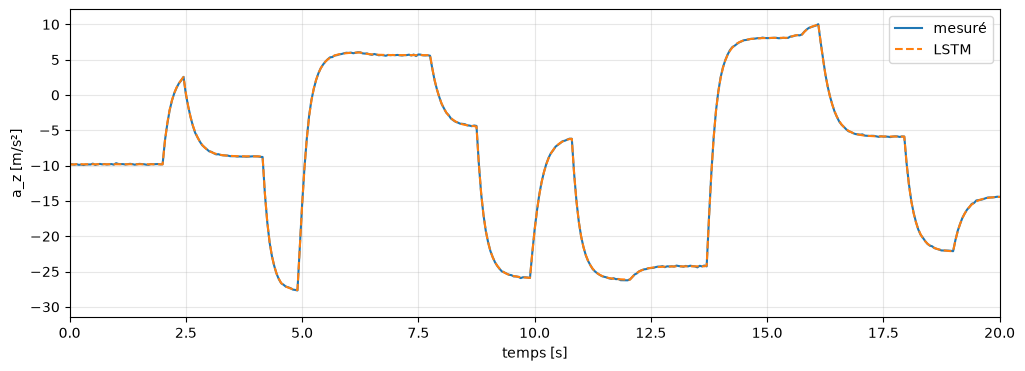

RMSE sur cette expérience : 0.049967586958883384 m/s²


In [27]:
model = model_nn.load_from_checkpoint(checkpoint.best_model_path)
model.eval()

i = 0                                                                     # une expérience de test
u_in = torch.tensor(Uc_test[i][None, :, None], dtype=torch.float32)       # expérience entière (100 s)
with torch.no_grad():
    pred_mm = model(u_in.to(model.device)).squeeze().cpu().numpy()

pred = scaler.inverse_transform(pred_mm.reshape(-1, 1)).ravel()           # retour en m/s²
t = np.arange(len(pred)) * Ts

plt.figure(figsize=(12, 4))
plt.plot(t, Yc_test[i], label="mesuré")
plt.plot(t, pred, "--", label="LSTM")
plt.xlim(0, 20); plt.xlabel("temps [s]"); plt.ylabel("a_z [m/s²]")
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

print("RMSE sur cette expérience :", np.sqrt(np.mean((pred - Yc_test[i]) ** 2)), "m/s²")

RMSE moyenne : 0.051 m/s²
RMSE max     : 0.057 m/s²  (expérience 332)


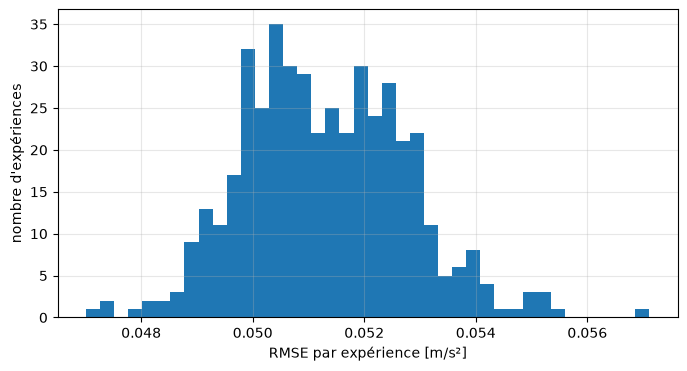

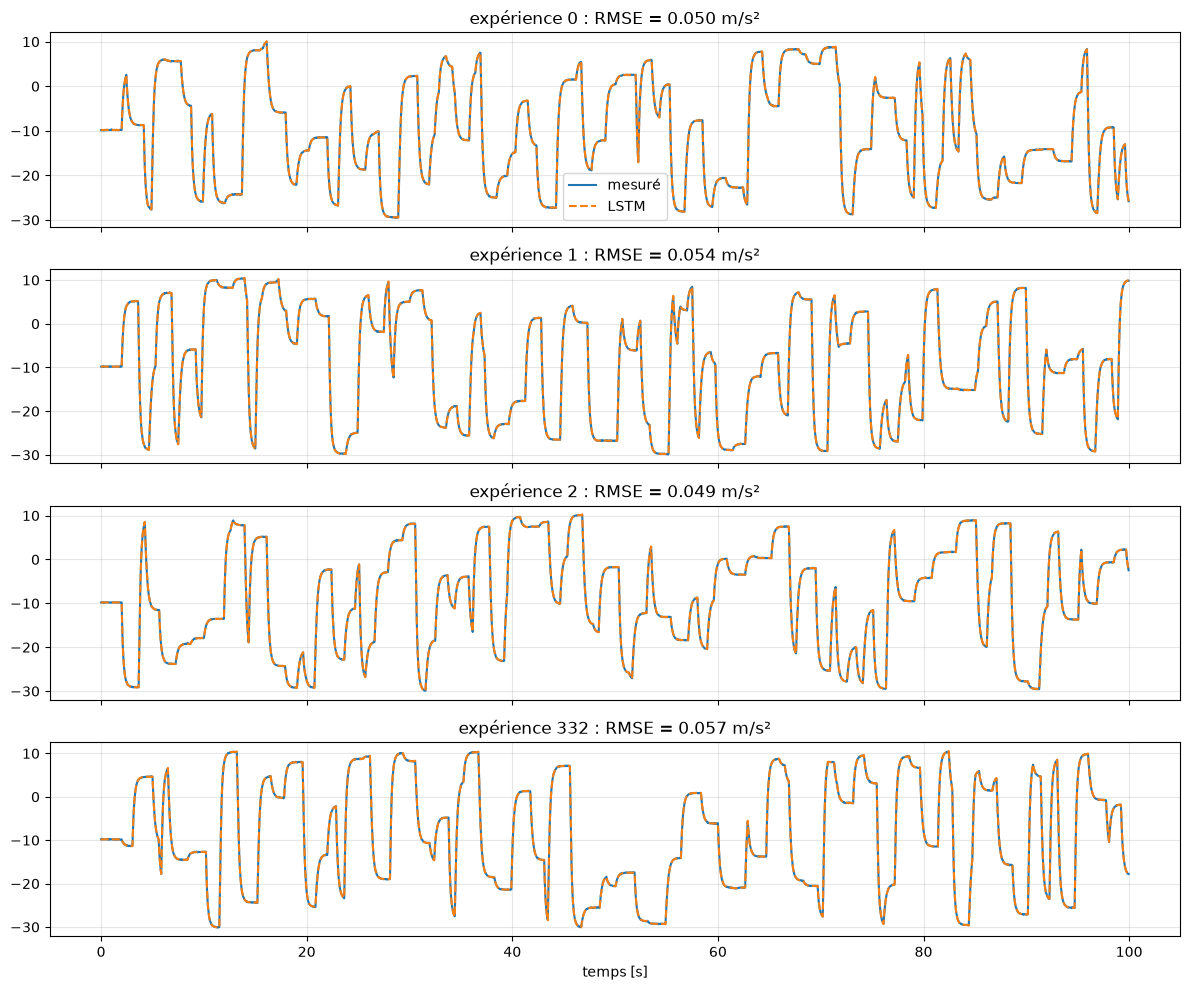

In [30]:
X_test_full = torch.tensor(Uc_test[:, :, None], dtype=torch.float32)    # (450, 2000, 1) : 100 s chacune
with torch.no_grad():
    pred_mm = model(X_test_full.to(model.device)).squeeze(-1).cpu().numpy()

pred_all = scaler.inverse_transform(pred_mm.reshape(-1, 1)).reshape(pred_mm.shape)   # en m/s²

rmse_par_exp = np.sqrt(np.mean((pred_all - Yc_test) ** 2, axis=1))   # une RMSE par expérience
print(f"RMSE moyenne : {rmse_par_exp.mean():.3f} m/s²")
print(f"RMSE max     : {rmse_par_exp.max():.3f} m/s²  (expérience {rmse_par_exp.argmax()})")

plt.figure(figsize=(8, 4))
plt.hist(rmse_par_exp, bins=40)
plt.xlabel("RMSE par expérience [m/s²]"); plt.ylabel("nombre d'expériences")
plt.grid(True, alpha=0.3); plt.show()

t = np.arange(Uc_test.shape[1]) * Ts
a_montrer = [0, 1, 2, rmse_par_exp.argmax()]          # 3 au hasard + la pire

fig, axes = plt.subplots(len(a_montrer), 1, figsize=(12, 10), sharex=True)
for ax, i in zip(axes, a_montrer):
    ax.plot(t, Yc_test[i], label="mesuré")
    ax.plot(t, pred_all[i], "--", label="LSTM")
    ax.set_title(f"expérience {i} : RMSE = {rmse_par_exp[i]:.3f} m/s²")
    ax.grid(True, alpha=0.3)
axes[0].legend(); axes[-1].set_xlabel("temps [s]")
plt.tight_layout(); plt.show()

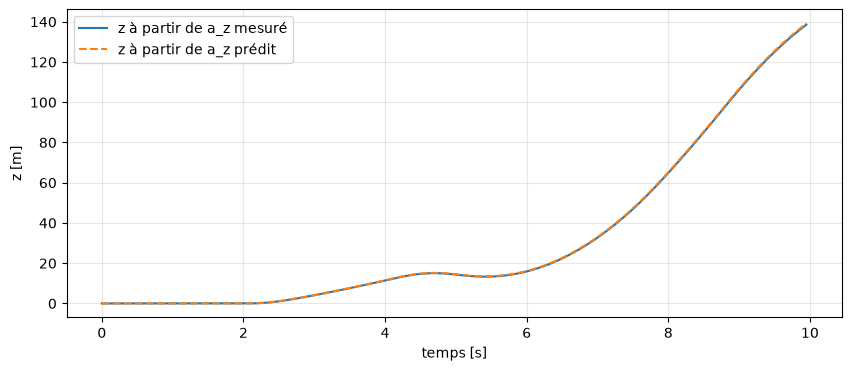

écart d'altitude à 10 s : 0.547 m


In [31]:
def integrer(a):
    vz = np.cumsum(a) * Ts       # vitesse : somme des accélérations x Ts
    z  = np.cumsum(vz) * Ts      # altitude : somme des vitesses x Ts
    return z

i = 0
duree = 200                      # 200 pas = 10 s, la durée de la mission
z_mesure = integrer(Yc_test[i, :duree] + 9.81)    # on retire la gravité... voir remarque
z_pred   = integrer(pred_all[i, :duree] + 9.81)

plt.figure(figsize=(10, 4))
plt.plot(t[:duree], z_mesure, label="z à partir de a_z mesuré")
plt.plot(t[:duree], z_pred, "--", label="z à partir de a_z prédit")
plt.xlabel("temps [s]"); plt.ylabel("z [m]"); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

print(f"écart d'altitude à 10 s : {abs(z_mesure[-1] - z_pred[-1]):.3f} m")

In [32]:
import os, shutil, json
os.makedirs("../models", exist_ok=True)
shutil.copy(checkpoint.best_model_path, "../models/lstm_az.ckpt")
json.dump({"a_min": float(scaler.data_min_[0]), "a_max": float(scaler.data_max_[0]), "Ts": Ts},
          open("../models/lstm_az_scaler.json", "w"), indent=2)